In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
file_path = "rides_train_sample.txt"

df = pd.read_csv(file_path)

print(df.shape)
print(df.columns)
df.head()

(1711257, 23)
Index(['Unnamed: 0.1', 'Unnamed: 0', 'VendorID', 'tpep_pickup_datetime',
       'tpep_dropoff_datetime', 'passenger_count', 'trip_distance',
       'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID',
       'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount',
       'tolls_amount', 'improvement_surcharge', 'total_amount',
       'congestion_surcharge', 'Airport_fee', 'duration_hours',
       'avg_speed_mph'],
      dtype='object')


,Unnamed: 0.1,Unnamed: 0,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,...,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,duration_hours,avg_speed_mph
0,1,2064199,2,2024-08-24 12:34:06,2024-08-24 12:38:59,1.0,0.66,1.0,False,231,...,0.0,0.5,2.10,0.0,1.0,12.60,2.5,0.0,0.081389,8.109215
1,2,435969,2,2024-07-07 02:33:02,2024-07-07 02:40:32,2.0,2.70,1.0,False,137,...,1.0,0.5,2.67,0.0,1.0,20.47,2.5,0.0,0.125000,21.600000
2,3,1974347,2,2024-02-21 17:29:39,2024-02-21 17:44:18,2.0,1.84,1.0,False,236,...,2.5,0.5,6.42,0.0,1.0,27.82,2.5,0.0,0.244167,7.535836
3,4,2870912,1,2024-07-11 23:39:43,2024-07-11 23:44:36,NaN,1.20,NaN,NaN,249,...,0.0,0.5,0.00,0.0,1.0,11.10,NaN,NaN,0.081389,14.744027
4,5,2285453,1,2024-11-21 11:42:59,2024-11-21 11:51:23,1.0,0.90,1.0,False,234,...,2.5,0.5,3.30,0.0,1.0,16.60,2.5,0.0,0.140000,6.428571


In [3]:
print("Shape:")
print(df.shape)

print("\nColumns:")
print(df.columns)

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isna().sum())

Shape:
(1711257, 23)

Columns:
Index(['Unnamed: 0.1', 'Unnamed: 0', 'VendorID', 'tpep_pickup_datetime',
       'tpep_dropoff_datetime', 'passenger_count', 'trip_distance',
       'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID',
       'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount',
       'tolls_amount', 'improvement_surcharge', 'total_amount',
       'congestion_surcharge', 'Airport_fee', 'duration_hours',
       'avg_speed_mph'],
      dtype='object')

Data types:
Unnamed: 0.1               int64
Unnamed: 0                 int64
VendorID                   int64
tpep_pickup_datetime      object
tpep_dropoff_datetime     object
passenger_count          float64
trip_distance            float64
RatecodeID               float64
store_and_fwd_flag        object
PULocationID               int64
DOLocationID               int64
payment_type               int64
fare_amount              float64
extra                    float64
mta_tax                  float6

In [4]:
df["tpep_pickup_datetime"] = pd.to_datetime(df["tpep_pickup_datetime"], errors="coerce")
df["tpep_dropoff_datetime"] = pd.to_datetime(df["tpep_dropoff_datetime"], errors="coerce")

print(df[["tpep_pickup_datetime", "tpep_dropoff_datetime"]].dtypes)
print(df[["tpep_pickup_datetime", "tpep_dropoff_datetime"]].isna().sum())

tpep_pickup_datetime     datetime64[ns]
tpep_dropoff_datetime    datetime64[ns]
dtype: object
tpep_pickup_datetime     0
tpep_dropoff_datetime    0
dtype: int64


In [5]:
df["trip_duration_min"] = (
    (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60
)

print(df["trip_duration_min"].describe())

print("\nInvalid duration checks:")
print("Negative duration trips:", (df["trip_duration_min"] < 0).sum())
print("Zero duration trips:", (df["trip_duration_min"] == 0).sum())
print("Trips longer than 180 min:", (df["trip_duration_min"] > 180).sum())

count    1.711257e+06
mean     1.453145e+01
std      1.081379e+01
min      1.666667e-02
25%      7.516667e+00
50%      1.201667e+01
75%      1.861667e+01
max      7.151167e+02
Name: trip_duration_min, dtype: float64

Invalid duration checks:
Negative duration trips: 0
Zero duration trips: 0
Trips longer than 180 min: 105


In [6]:
numeric_cols = ["trip_distance", "fare_amount", "total_amount", "tip_amount"]
print(df[numeric_cols].describe())

print("\nSuspicious numeric values:")
print("Negative trip distance:", (df["trip_distance"] < 0).sum())
print("Zero trip distance:", (df["trip_distance"] == 0).sum())

print("Negative fare amount:", (df["fare_amount"] < 0).sum())
print("Zero fare amount:", (df["fare_amount"] == 0).sum())

print("Negative total amount:", (df["total_amount"] < 0).sum())
print("Zero total amount:", (df["total_amount"] == 0).sum())

print("Negative tip amount:", (df["tip_amount"] < 0).sum())

       trip_distance   fare_amount  total_amount    tip_amount
count   1.711257e+06  1.711257e+06  1.711257e+06  1.711257e+06
mean    2.418266e+00  1.608507e+01  2.390466e+01  2.884333e+00
std     2.750285e+00  1.199631e+01  1.493307e+01  3.010868e+00
min     1.000000e-02  0.000000e+00  0.000000e+00  0.000000e+00
25%     1.000000e+00  9.300000e+00  1.560000e+01  0.000000e+00
50%     1.610000e+00  1.280000e+01  2.015000e+01  2.650000e+00
75%     2.700000e+00  1.910000e+01  2.710000e+01  4.000000e+00
max     1.879100e+02  7.779000e+02  8.112200e+02  2.156600e+02

Suspicious numeric values:
Negative trip distance: 0
Zero trip distance: 0
Negative fare amount: 0
Zero fare amount: 320
Negative total amount: 0
Zero total amount: 68
Negative tip amount: 0


# Clean the trip-level data

In [9]:
def clean_trip_level_data(df):
    df = df.copy()

    # convert datetimes
    df["tpep_pickup_datetime"] = pd.to_datetime(df["tpep_pickup_datetime"], errors="coerce")
    df["tpep_dropoff_datetime"] = pd.to_datetime(df["tpep_dropoff_datetime"], errors="coerce")

    # trip duration
    df["trip_duration_min"] = (
        (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60
    )

    # basic cleaning
    df = df[
        df["tpep_pickup_datetime"].notna() &
        df["tpep_dropoff_datetime"].notna() &
        (df["trip_duration_min"] > 0) &
        (df["trip_distance"] >= 0) &
        (df["fare_amount"] >= 0) &
        (df["total_amount"] >= 0) &
        (df["tip_amount"] >= 0)
    ].copy()

    return df

In [11]:
df_clean = clean_trip_level_data(df)

print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)
print("Rows removed:", df.shape[0] - df_clean.shape[0])

Original shape: (1711257, 24)
Cleaned shape: (1711257, 24)
Rows removed: 0


# Manhattan filtering

In [12]:
manhattan_zones = [
    4, 12, 13, 24, 41, 42, 43, 45, 48, 50,
    68, 74, 75, 79, 87, 88, 90, 100, 107, 113,
    114, 116, 120, 125, 137, 140, 141, 142, 143,
    144, 148, 151, 152, 158, 161, 162, 163, 164,
    166, 170, 186, 194, 202, 209, 211, 224, 229,
    230, 231, 232, 233, 234, 236, 237, 238, 239,
    246, 249, 261, 262, 263
]

def filter_manhattan(df):
    return df[df["PULocationID"].isin(manhattan_zones)].copy()

df_manhattan = filter_manhattan(df_clean)

print("Cleaned rows:", df_clean.shape[0])
print("Manhattan rows:", df_manhattan.shape[0])

Cleaned rows: 1711257
Manhattan rows: 1709073


In [15]:
df_manhattan.head()

,Unnamed: 0.1,Unnamed: 0,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,...,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,duration_hours,avg_speed_mph,trip_duration_min
0,1,2064199,2,2024-08-24 12:34:06,2024-08-24 12:38:59,1.0,0.66,1.0,False,231,...,0.5,2.10,0.0,1.0,12.60,2.5,0.0,0.081389,8.109215,4.883333
1,2,435969,2,2024-07-07 02:33:02,2024-07-07 02:40:32,2.0,2.70,1.0,False,137,...,0.5,2.67,0.0,1.0,20.47,2.5,0.0,0.125000,21.600000,7.500000
2,3,1974347,2,2024-02-21 17:29:39,2024-02-21 17:44:18,2.0,1.84,1.0,False,236,...,0.5,6.42,0.0,1.0,27.82,2.5,0.0,0.244167,7.535836,14.650000
3,4,2870912,1,2024-07-11 23:39:43,2024-07-11 23:44:36,NaN,1.20,NaN,NaN,249,...,0.5,0.00,0.0,1.0,11.10,NaN,NaN,0.081389,14.744027,4.883333
4,5,2285453,1,2024-11-21 11:42:59,2024-11-21 11:51:23,1.0,0.90,1.0,False,234,...,0.5,3.30,0.0,1.0,16.60,2.5,0.0,0.140000,6.428571,8.400000


# Aggregate to zone-hour (creating the target variable)

In [54]:
def aggregate_zone_hour(df):
    df = df.copy()
    df["pickup_hour_dt"] = df["tpep_pickup_datetime"].dt.floor("h")

    zone_hour = df.groupby(
        ["PULocationID", "pickup_hour_dt"]
    ).agg(
        trip_count=("VendorID", "count"), # 
        total_revenue=("total_amount", "sum")
    ).reset_index()

    return zone_hour

df_zone_hour = aggregate_zone_hour(df_manhattan)

print(df_zone_hour.shape)
df_zone_hour.head()

(276210, 4)


,PULocationID,pickup_hour_dt,trip_count,total_revenue
0,4,2024-01-01 01:00:00,3,59.68
1,4,2024-01-01 02:00:00,8,251.59
2,4,2024-01-01 04:00:00,2,37.34
3,4,2024-01-01 06:00:00,1,20.60
4,4,2024-01-01 17:00:00,2,84.04


# Create full zone-hour grid

### This ensures the model sees:

demand hours
zero-demand hours

In [55]:
def make_full_zone_hour_grid(df_zone_hour):
    all_zones = sorted(df_zone_hour["PULocationID"].unique())
    all_hours = pd.date_range(
        start=df_zone_hour["pickup_hour_dt"].min(),
        end=df_zone_hour["pickup_hour_dt"].max(),
        freq="h"
    )

    full_index = pd.MultiIndex.from_product(
        [all_zones, all_hours],
        names=["PULocationID", "pickup_hour_dt"]
    )

    out = (
        df_zone_hour
        .set_index(["PULocationID", "pickup_hour_dt"])
        .reindex(full_index)
        .reset_index()
    )

    out["trip_count"] = out["trip_count"].fillna(0)
    out["total_revenue"] = out["total_revenue"].fillna(0)

    return out

df_zone_hour_full = df_zone_hour.copy()

print(df_zone_hour_full.shape)
df_zone_hour_full.head()

(276210, 4)


,PULocationID,pickup_hour_dt,trip_count,total_revenue
0,4,2024-01-01 01:00:00,3,59.68
1,4,2024-01-01 02:00:00,8,251.59
2,4,2024-01-01 04:00:00,2,37.34
3,4,2024-01-01 06:00:00,1,20.60
4,4,2024-01-01 17:00:00,2,84.04


# Adding time features 

In [56]:
def add_time_features(df):
    df = df.copy()

    df["hour"] = df["pickup_hour_dt"].dt.hour
    df["dayofweek"] = df["pickup_hour_dt"].dt.dayofweek
    df["day"] = df["pickup_hour_dt"].dt.day
    df["month"] = df["pickup_hour_dt"].dt.month
    df["is_weekend"] = df["dayofweek"].isin([5, 6]).astype(int)

    return df

df_zone_hour_full = add_time_features(df_zone_hour_full)

# Adding lag and rolling features?

In [57]:
def add_lag_and_rolling_features(
    df,
    group_col="PULocationID",
    time_col="pickup_hour_dt",
    target_cols=("trip_count", "total_revenue"),
    lags=(1, 24, 168),
    rolling_windows=(3, 24)
):
    df = df.copy()
    df = df.sort_values([group_col, time_col])

    for target in target_cols:
        # lag features
        for lag in lags:
            df[f"{target}_lag_{lag}"] = (
                df.groupby(group_col)[target].shift(lag)
            )

        # leakage-safe rolling features
        for window in rolling_windows:
            df[f"{target}_roll_{window}"] = (
                df.groupby(group_col)[target]
                .shift(1)
                .rolling(window)
                .mean()
                .reset_index(level=0, drop=True)
            )

    return df

In [58]:
df_final = add_lag_and_rolling_features(df_zone_hour_full)

print(df_final.shape)
df_final.head()

(276210, 19)


,PULocationID,pickup_hour_dt,trip_count,total_revenue,hour,dayofweek,day,month,is_weekend,trip_count_lag_1,trip_count_lag_24,trip_count_lag_168,trip_count_roll_3,trip_count_roll_24,total_revenue_lag_1,total_revenue_lag_24,total_revenue_lag_168,total_revenue_roll_3,total_revenue_roll_24
0,4,2024-01-01 01:00:00,3,59.68,1,0,1,1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,4,2024-01-01 02:00:00,8,251.59,2,0,1,1,0,3.0,NaN,NaN,NaN,NaN,59.68,NaN,NaN,NaN,NaN
2,4,2024-01-01 04:00:00,2,37.34,4,0,1,1,0,8.0,NaN,NaN,NaN,NaN,251.59,NaN,NaN,NaN,NaN
3,4,2024-01-01 06:00:00,1,20.60,6,0,1,1,0,2.0,NaN,NaN,4.333333,NaN,37.34,NaN,NaN,116.203333,NaN
4,4,2024-01-01 17:00:00,2,84.04,17,0,1,1,0,1.0,NaN,NaN,3.666667,NaN,20.60,NaN,NaN,103.176667,NaN


In [59]:
df_final["trip_count"].value_counts()

trip_count
1     58657
2     37303
3     27421
4     22504
5     18803
6     15950
7     13846
8     12056
9     10384
10     8850
11     7842
12     6363
13     5660
14     4668
15     3897
16     3333
17     2817
18     2398
19     1968
20     1612
21     1372
22     1213
23     1048
24      900
25      792
26      647
27      532
28      506
29      414
30      364
31      319
32      286
33      218
34      199
35      187
36      144
37      131
39       90
38       90
41       73
40       72
42       61
43       49
44       32
46       27
47       24
45       24
48       18
49       11
51        7
50        7
53        4
52        3
56        3
54        3
55        3
58        2
57        1
59        1
78        1
Name: count, dtype: int64

# MASTER PREPROCESSING FUNCTION

In [60]:
def preprocess_taxi_data(file_path, make_full_grid=False):
    df = pd.read_csv(file_path)

    df_clean = clean_trip_level_data(df)
    df_manhattan = filter_manhattan(df_clean)
    df_zone_hour = aggregate_zone_hour(df_manhattan)

    if make_full_grid:
        df_zone_hour_full = make_full_zone_hour_grid(df_zone_hour)
    else:
        # for sampled / incomplete data
        df_zone_hour_full = df_zone_hour.copy()

    df_zone_hour_full = add_time_features(df_zone_hour_full)
    df_final = add_lag_and_rolling_features(df_zone_hour_full)

    return df_final

In [61]:
df_final = preprocess_taxi_data("rides_train_sample.txt", make_full_grid=False)
print(df_final.shape)
df_final.head()

(276210, 19)


,PULocationID,pickup_hour_dt,trip_count,total_revenue,hour,dayofweek,day,month,is_weekend,trip_count_lag_1,trip_count_lag_24,trip_count_lag_168,trip_count_roll_3,trip_count_roll_24,total_revenue_lag_1,total_revenue_lag_24,total_revenue_lag_168,total_revenue_roll_3,total_revenue_roll_24
0,4,2024-01-01 01:00:00,3,59.68,1,0,1,1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,4,2024-01-01 02:00:00,8,251.59,2,0,1,1,0,3.0,NaN,NaN,NaN,NaN,59.68,NaN,NaN,NaN,NaN
2,4,2024-01-01 04:00:00,2,37.34,4,0,1,1,0,8.0,NaN,NaN,NaN,NaN,251.59,NaN,NaN,NaN,NaN
3,4,2024-01-01 06:00:00,1,20.60,6,0,1,1,0,2.0,NaN,NaN,4.333333,NaN,37.34,NaN,NaN,116.203333,NaN
4,4,2024-01-01 17:00:00,2,84.04,17,0,1,1,0,1.0,NaN,NaN,3.666667,NaN,20.60,NaN,NaN,103.176667,NaN


# Correlation of candidate lag features

In [72]:
candidate_cols = [
    "trip_count_lag_1", "trip_count_lag_24", "trip_count_lag_168",
    "trip_count_roll_3", "trip_count_roll_24",
    "total_revenue_lag_1", "total_revenue_lag_24", "total_revenue_lag_168",
    "total_revenue_roll_3", "total_revenue_roll_24"
]

print(df_final[["trip_count", "total_revenue"] + candidate_cols].corr()[["trip_count", "total_revenue"]])

                       trip_count  total_revenue
trip_count               1.000000       0.954525
total_revenue            0.954525       1.000000
trip_count_lag_1         0.790101       0.748941
trip_count_lag_24        0.552899       0.523987
trip_count_lag_168       0.392866       0.369911
trip_count_roll_3        0.754515       0.713514
trip_count_roll_24       0.650807       0.614869
total_revenue_lag_1      0.757481       0.743399
total_revenue_lag_24     0.536275       0.525763
total_revenue_lag_168    0.365732       0.356179
total_revenue_roll_3     0.742197       0.726323
total_revenue_roll_24    0.636643       0.624625


# Distribution of trip_count

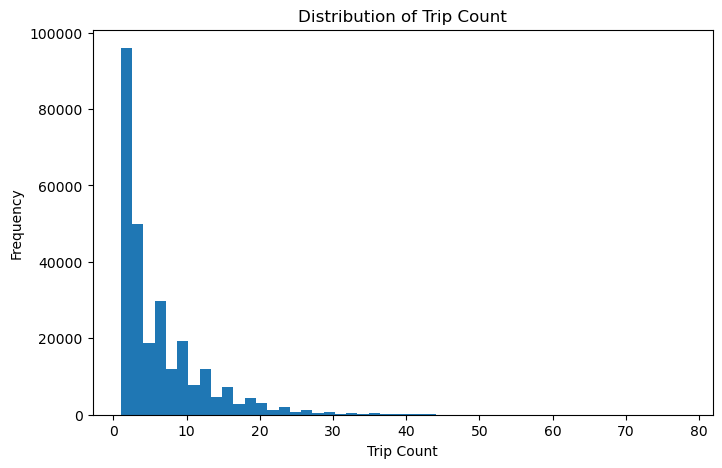

In [62]:
plt.figure(figsize=(8, 5))
plt.hist(df_final["trip_count"], bins=50)
plt.title("Distribution of Trip Count")
plt.xlabel("Trip Count")
plt.ylabel("Frequency")
plt.show()

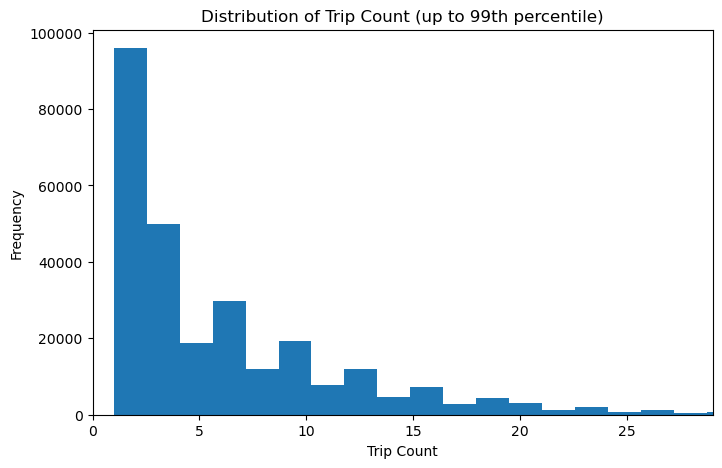

In [63]:
plt.figure(figsize=(8, 5))
plt.hist(df_final["trip_count"], bins=50)
plt.xlim(0, df_final["trip_count"].quantile(0.99))
plt.title("Distribution of Trip Count (up to 99th percentile)")
plt.xlabel("Trip Count")
plt.ylabel("Frequency")
plt.show()

In [64]:
(df_final["trip_count"] == 2).sum()

np.int64(37303)

# Demand by hour with variability bands

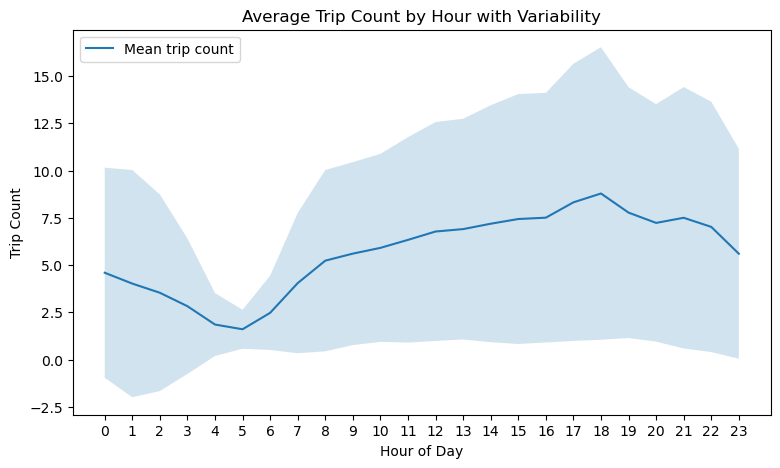

In [65]:
hour_stats = df_final.groupby("hour")["trip_count"].agg(["mean", "std"]).reset_index()

plt.figure(figsize=(9, 5))
plt.plot(hour_stats["hour"], hour_stats["mean"], label="Mean trip count")
plt.fill_between(
    hour_stats["hour"],
    hour_stats["mean"] - hour_stats["std"],
    hour_stats["mean"] + hour_stats["std"],
    alpha=0.2
)
plt.title("Average Trip Count by Hour with Variability")
plt.xlabel("Hour of Day")
plt.ylabel("Trip Count")
plt.xticks(range(24))
plt.legend()
plt.show()

morning and evening peaks

overnight troughs

some hours have unstable demand even if average is high

# Weekday vs Weekend hourly demand

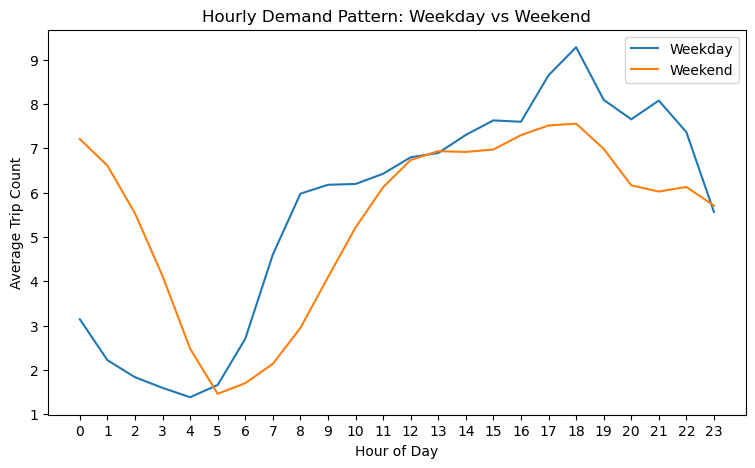

In [66]:
weekday_hour = (
    df_final.groupby(["is_weekend", "hour"])["trip_count"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(9, 5))

for weekend_flag, label in [(0, "Weekday"), (1, "Weekend")]:
    subset = weekday_hour[weekday_hour["is_weekend"] == weekend_flag]
    plt.plot(subset["hour"], subset["trip_count"], label=label)

plt.title("Hourly Demand Pattern: Weekday vs Weekend")
plt.xlabel("Hour of Day")
plt.ylabel("Average Trip Count")
plt.xticks(range(24))
plt.legend()
plt.show()

# Heatmap: day of week × hour

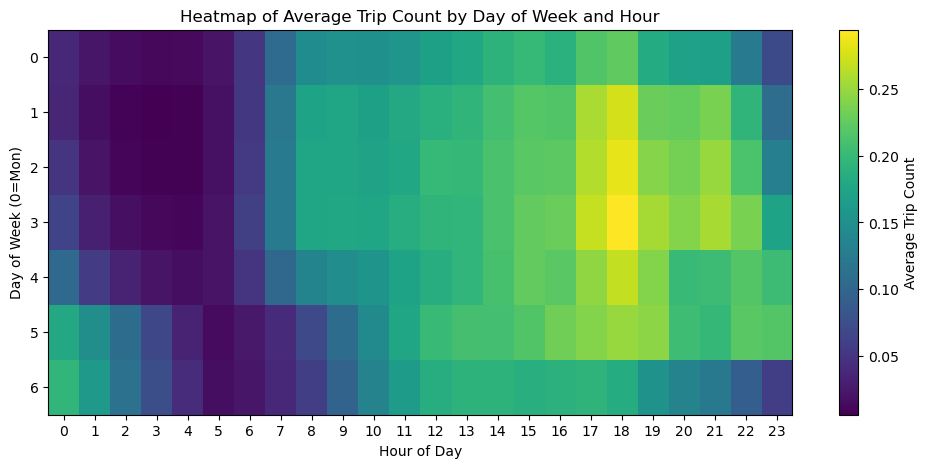

In [33]:
pivot_dow_hour = df_final.pivot_table(
    values="trip_count",
    index="dayofweek",
    columns="hour",
    aggfunc="mean"
)

plt.figure(figsize=(12, 5))
plt.imshow(pivot_dow_hour, aspect="auto")
plt.colorbar(label="Average Trip Count")
plt.title("Heatmap of Average Trip Count by Day of Week and Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Day of Week (0=Mon)")
plt.xticks(range(24))
plt.yticks(range(7))
plt.show()

# Daily total demand over the month

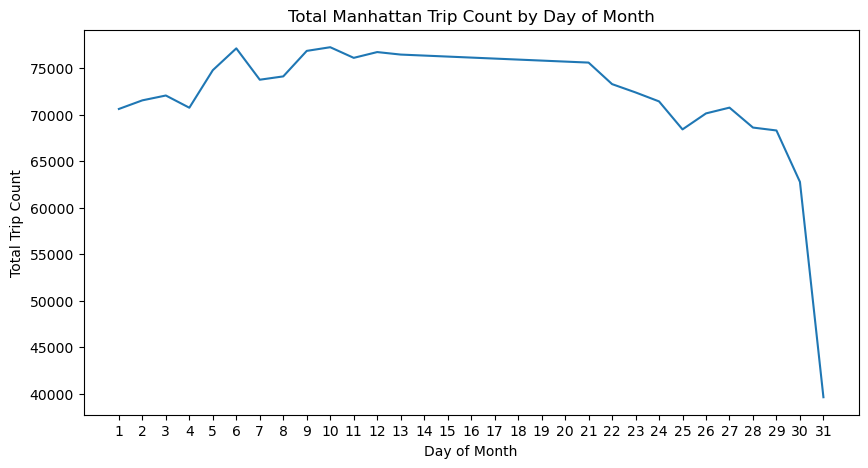

In [67]:
daily_total = df_final.groupby("day")["trip_count"].sum()

plt.figure(figsize=(10, 5))
daily_total.plot()
plt.title("Total Manhattan Trip Count by Day of Month")
plt.xlabel("Day of Month")
plt.ylabel("Total Trip Count")
plt.xticks(range(1, 32))
plt.show()

# Zone ranking: average demand and volatility 

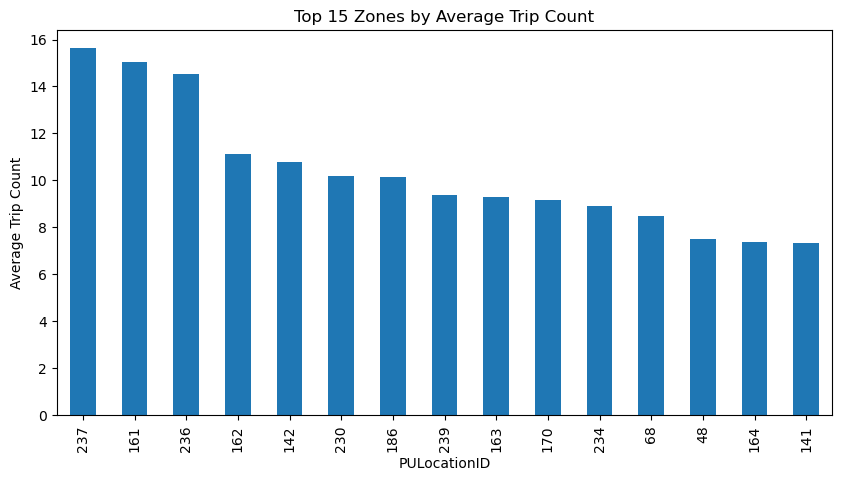

In [68]:
zone_mean = df_final.groupby("PULocationID")["trip_count"].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
zone_mean.head(15).plot(kind="bar")
plt.title("Top 15 Zones by Average Trip Count")
plt.ylabel("Average Trip Count")
plt.xlabel("PULocationID")
plt.show()

# Demand volatility by zone

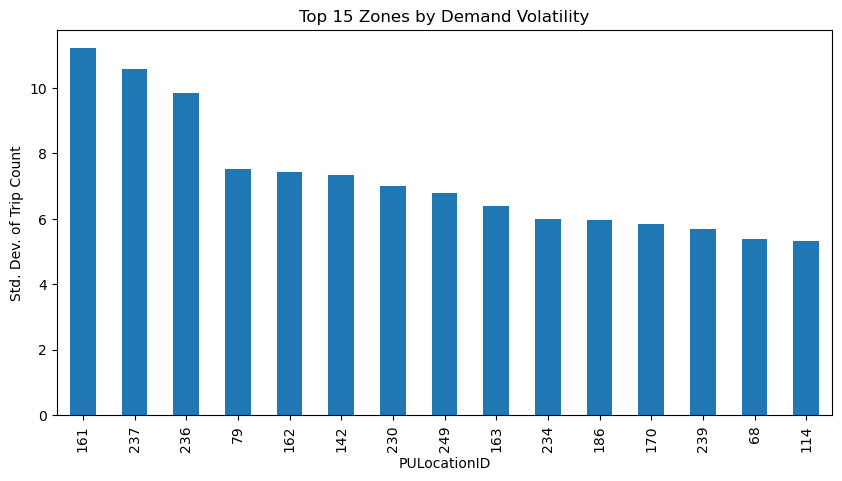

In [69]:
zone_std = df_final.groupby("PULocationID")["trip_count"].std().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
zone_std.head(15).plot(kind="bar")
plt.title("Top 15 Zones by Demand Volatility")
plt.ylabel("Std. Dev. of Trip Count")
plt.xlabel("PULocationID")
plt.show()

# Demand concentration curve

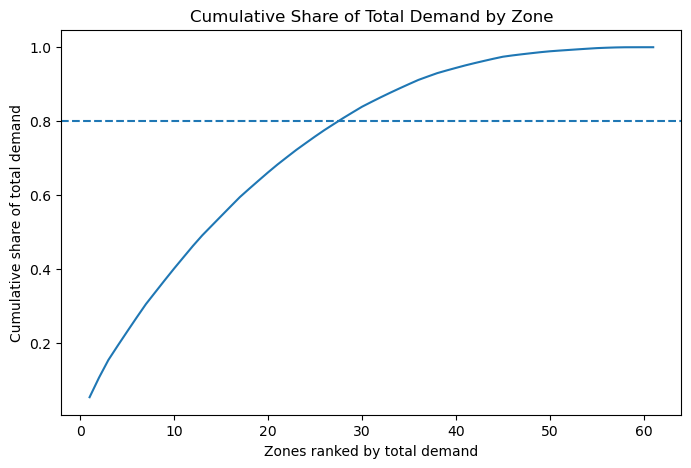

In [74]:
zone_total = df_final.groupby("PULocationID")["trip_count"].sum().sort_values(ascending=False)
cum_share = zone_total.cumsum() / zone_total.sum()

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cum_share) + 1), cum_share.values)
plt.title("Cumulative Share of Total Demand by Zone")
plt.xlabel("Zones ranked by total demand")
plt.ylabel("Cumulative share of total demand")
plt.axhline(0.8, linestyle="--")
plt.show()

# Lag relationship plots

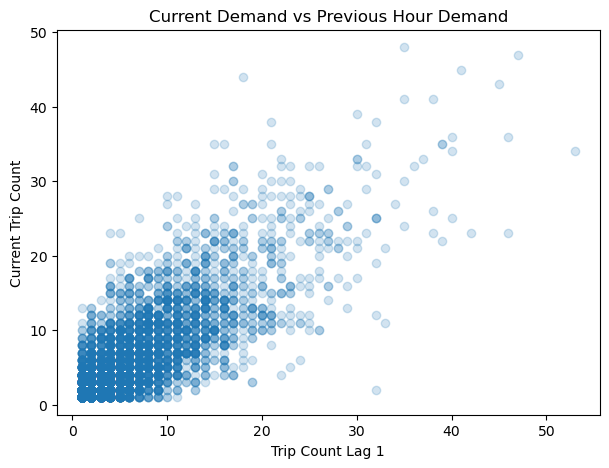

In [75]:
sample_df = df_final[["trip_count", "trip_count_lag_1"]].dropna().sample(
    min(5000, len(df_final[["trip_count", "trip_count_lag_1"]].dropna())),
    random_state=42
)

plt.figure(figsize=(7, 5))
plt.scatter(sample_df["trip_count_lag_1"], sample_df["trip_count"], alpha=0.2)
plt.xlabel("Trip Count Lag 1")
plt.ylabel("Current Trip Count")
plt.title("Current Demand vs Previous Hour Demand")
plt.show()

# Boxplots by hour

C:\Users\pc\AppData\Local\Temp\ipykernel_37588\1671568453.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(hour_data, labels=range(24), showfliers=False)


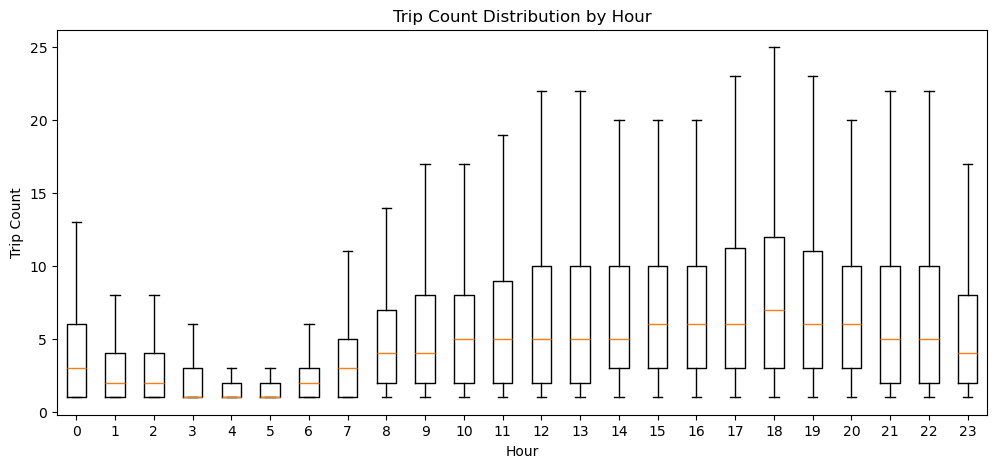

In [77]:
hour_data = [df_final[df_final["hour"] == h]["trip_count"].values for h in range(24)]

plt.figure(figsize=(12, 5))
plt.boxplot(hour_data, labels=range(24), showfliers=False)
plt.title("Trip Count Distribution by Hour")
plt.xlabel("Hour")
plt.ylabel("Trip Count")
plt.show()

# Baseline model

In [78]:
df_final = df_final.sort_values(["PULocationID", "pickup_hour_dt"])

In [79]:
df_model = df_final.dropna().copy()
print(df_model.shape)

(266264, 19)


In [83]:
target = "trip_count"

features = [
    "hour", "dayofweek", "month", "is_weekend",
    "trip_count_lag_1", "trip_count_lag_24",
    "trip_count_roll_3", "trip_count_roll_24",
    "total_revenue_roll_3", "total_revenue_roll_24"
]

In [84]:
split_date = df_model["pickup_hour_dt"].quantile(0.8)

train = df_model[df_model["pickup_hour_dt"] <= split_date]
test  = df_model[df_model["pickup_hour_dt"] > split_date]

print(train.shape, test.shape)

(213013, 19) (53251, 19)


In [85]:
from sklearn.linear_model import LinearRegression

X_train = train[features]
y_train = train[target]

X_test = test[features]
y_test = test[target]

model = LinearRegression()
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [86]:
y_pred = model.predict(X_test)

In [87]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.3f}")

MAE  : 2.55
RMSE : 3.67
R²   : 0.679


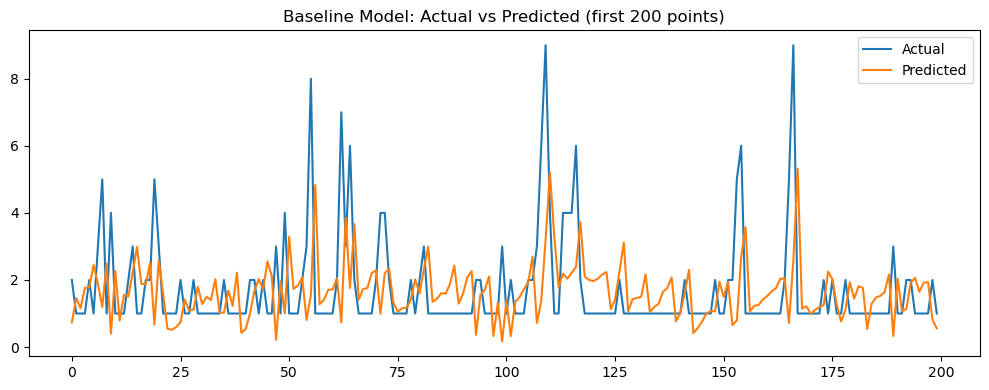

In [88]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(y_test.values[:200], label="Actual")
plt.plot(y_pred[:200], label="Predicted")
plt.legend()
plt.title("Baseline Model: Actual vs Predicted (first 200 points)")
plt.tight_layout()
plt.show()